# Project 16: Part of Speech Tagging via HMM and BiLSTM
## AML Part (Phase 1): HMM + Viterbi Baseline

**Goal:** Assign a grammatical tag (NOUN, VERB, DET, ...) to every word in an English sentence using a Hidden Markov Model decoded with the Viterbi algorithm.

**Dataset:** Universal Dependencies English EWT (official train / dev / test split)

**This notebook covers:**
1. Downloading and loading the data
2. Building the vocabulary (rare words mapped to `<UNK>`)
3. Counting transitions and emissions
4. Smoothing, Viterbi and evaluation (in the next sections)

## 0. Setup

`conllu` is a library that reads `.conllu` files. It is not pre-installed in Colab, so we install it first.

In [3]:
!pip install conllu

### Imports

- `Counter`: counting words and tags
- `numpy`: building the count tables (matrices)
- `parse_incr`: reading a `.conllu` file sentence by sentence

In [4]:
import os
import urllib.request
from collections import Counter

import numpy as np
from conllu import parse_incr

## 1. Dataset Download

The dataset is **UD English EWT**, from the official GitHub repo: https://github.com/UniversalDependencies/UD_English-EWT

We need 3 files: `train` (for learning the model), `dev` (for tuning), and `test` (for the final result). All three are saved in the `data/` folder. If a file already exists, it is not downloaded again.

**Version:** UD English EWT v2.18 (as listed in the repo README when downloaded). License: CC BY-SA 4.0.

In [5]:
BASE = "https://raw.githubusercontent.com/UniversalDependencies/UD_English-EWT/master/"
DATA_DIR = "data"
FILES = {s: f"en_ewt-ud-{s}.conllu" for s in ("train", "dev", "test")}

os.makedirs(DATA_DIR, exist_ok=True)
for split, fname in FILES.items():
    path = os.path.join(DATA_DIR, fname)
    if not os.path.exists(path):
        print(f"Downloading {fname} ...")
        urllib.request.urlretrieve(BASE + fname, path)
    else:
        print(f"{fname} already exists")

## 2. Data Loading

Each sentence is converted into a list of `(word, tag)` pairs.

**Things to note:**
- Multiword tokens (ids like `1-2`) and empty nodes (ids like `8.1`) are **skipped**, otherwise words and tags would get misaligned.
- `LOWERCASE = True` means all words are lowercased. We will compare with `False` later.
- The tag set is built from **train only**.

**Expected output:** 12544 train, 2001 dev, 2077 test sentences, and 17 tags.

In [6]:
LOWERCASE = True  # lowercase all words (we will compare with False later)

def load_conllu(path, lowercase=LOWERCASE):
    """Har sentence = [(word, upos), ...]. Multiword tokens (1-2) aur empty nodes (8.1) skip."""
    sentences = []
    with open(path, encoding="utf-8") as f:
        for sent in parse_incr(f):
            pairs = []
            for tok in sent:
                if not isinstance(tok["id"], int):
                    continue
                word = tok["form"].lower() if lowercase else tok["form"]
                pairs.append((word, tok["upos"]))
            if pairs:
                sentences.append(pairs)
    return sentences


train = load_conllu(os.path.join(DATA_DIR, FILES["train"]))
dev = load_conllu(os.path.join(DATA_DIR, FILES["dev"]))
test = load_conllu(os.path.join(DATA_DIR, FILES["test"]))

print("Sentences  -> train:", len(train), "| dev:", len(dev), "| test:", len(test))
print("Tokens     -> train:", sum(map(len, train)), "| dev:", sum(map(len, dev)), "| test:", sum(map(len, test)))
print("\nExample sentence:", train[0])

tag_counts = Counter(t for sent in train for _, t in sent)
tags = sorted(tag_counts)
tag2id = {t: i for i, t in enumerate(tags)}
n_tags = len(tags)
print(f"\n{n_tags} tags:", tags)
print("Most common:", tag_counts.most_common(5))

Sentences  -> train: 12544 | dev: 2001 | test: 2077
Tokens     -> train: 204578 | dev: 25148 | test: 25094

Example sentence: [('al', 'PROPN'), ('-', 'PUNCT'), ('zaman', 'PROPN'), (':', 'PUNCT'), ('american', 'ADJ'), ('forces', 'NOUN'), ('killed', 'VERB'), ('shaikh', 'PROPN'), ('abdullah', 'PROPN'), ('al', 'PROPN'), ('-', 'PUNCT'), ('ani', 'PROPN'), (',', 'PUNCT'), ('the', 'DET'), ('preacher', 'NOUN'), ('at', 'ADP'), ('the', 'DET'), ('mosque', 'NOUN'), ('in', 'ADP'), ('the', 'DET'), ('town', 'NOUN'), ('of', 'ADP'), ('qaim', 'PROPN'), (',', 'PUNCT'), ('near', 'ADP'), ('the', 'DET'), ('syrian', 'ADJ'), ('border', 'NOUN'), ('.', 'PUNCT')]

17 tags: ['ADJ', 'ADP', 'ADV', 'AUX', 'CCONJ', 'DET', 'INTJ', 'NOUN', 'NUM', 'PART', 'PRON', 'PROPN', 'PUNCT', 'SCONJ', 'SYM', 'VERB', 'X']
Most common: [('NOUN', 34751), ('PUNCT', 23596), ('VERB', 22576), ('PRON', 18678), ('ADP', 17714)]


## 3. Vocabulary and `<UNK>`

The vocabulary is built **from the train data only**. Building it from dev or test would cause data leakage.

**Why `<UNK>`?** Any word seen fewer than 2 times in train is replaced with `<UNK>`. This gives the model examples of what unknown words look like (which tags they tend to have). Without it, new words at test time would get probability 0.

**OOV rate** = the share of test words never seen in train. We will use it later for the "unknown word accuracy" metric.

**Expected output:** vocab size 8866, OOV rate 6.79% (dev) and 7.50% (test).

In [7]:
UNK = "<UNK>"
MIN_FREQ = 2   # words seen fewer than 2 times in train -> <UNK>

word_counts = Counter(w for sent in train for w, _ in sent)
train_words = set(word_counts)
vocab = [UNK] + sorted(w for w, c in word_counts.items() if c >= MIN_FREQ)
word2id = {w: i for i, w in enumerate(vocab)}
n_vocab = len(vocab)
UNK_ID = word2id[UNK]


def to_id(word):
    return word2id.get(word, UNK_ID)


hapax = sum(1 for c in word_counts.values() if c < MIN_FREQ)
print(f"Distinct words in train: {len(word_counts)}")
print(f"Vocab size (freq >= {MIN_FREQ} + <UNK>): {n_vocab}")
print(f"Words turned into <UNK> in train: {hapax}")


def oov_rate(sentences):
    toks = [w for sent in sentences for w, _ in sent]
    return sum(w not in train_words for w in toks) / len(toks)


print(f"OOV rate -> dev: {oov_rate(dev):.2%} | test: {oov_rate(test):.2%}")

Distinct words in train: 16654
Vocab size (freq >= 2 + <UNK>): 8866
Words turned into <UNK> in train: 7789
OOV rate -> dev: 6.79% | test: 7.50%


## 4. Counts: Transition and Emission

What the HMM learns:

- **Transition counts:** how often one tag follows another (e.g. NOUN after DET)
- **Emission counts:** how often a word appears with a tag (e.g. "time" with NOUN)
- `<START>` and `<END>` are two extra states marking the beginning and end of a sentence

**Shapes:** transition `(19, 19)` (17 tags + START + END), emission `(17, 8866)` (17 tags x vocabulary size).

In [8]:
START, END = n_tags, n_tags + 1
trans_counts = np.zeros((n_tags + 2, n_tags + 2))   # [from_state, to_state]
emit_counts = np.zeros((n_tags, n_vocab))           # [tag, word_id]

for sent in train:
    prev = START
    for word, tag in sent:
        t = tag2id[tag]
        trans_counts[prev, t] += 1
        emit_counts[t, to_id(word)] += 1
        prev = t
    trans_counts[prev, END] += 1

print("trans_counts shape:", trans_counts.shape, "| emit_counts shape:", emit_counts.shape)

trans_counts shape: (19, 19) | emit_counts shape: (17, 8866)


## 5. Sanity Checks

Before moving on, we verify that the counting is correct:
- Total emission counts = total number of train tokens
- Every sentence starts from `<START>` exactly once
- Nothing transitions into `<START>`, and nothing transitions out of `<END>`

Below, we also peek at what the model learned. For example, "about 59% of the time a NOUN follows a DET" is a grammar pattern that came straight from the data.

**Expected output:** `All sanity checks passed.`

In [9]:
n_train_tokens = sum(map(len, train))
assert emit_counts.sum() == n_train_tokens
assert trans_counts.sum() == n_train_tokens + len(train)
assert trans_counts[START].sum() == len(train)
assert trans_counts[:, START].sum() == 0 and trans_counts[END].sum() == 0
print("All sanity checks passed.")

name = lambda i: "<START>" if i == START else "<END>" if i == END else tags[i]


def top_next(tag, k=4):
    row = trans_counts[tag2id[tag]]
    return [(name(j), round(float(row[j] / row.sum()), 3)) for j in np.argsort(-row)[:k]]


def top_words(tag, k=6):
    row = emit_counts[tag2id[tag]]
    return [(vocab[j], round(float(row[j] / row.sum()), 4)) for j in np.argsort(-row)[:k]]


print("\nAfter DET, next tag:", top_next("DET"))
print("After ADJ, next tag:", top_next("ADJ"))
print("Top words for NOUN :", top_words("NOUN"))
print("Top words for VERB :", top_words("VERB"))

All sanity checks passed.

After DET, next tag: [('NOUN', 0.594), ('ADJ', 0.234), ('PROPN', 0.077), ('VERB', 0.019)]
After ADJ, next tag: [('NOUN', 0.518), ('PUNCT', 0.128), ('ADP', 0.079), ('PROPN', 0.066)]
Top words for NOUN : [('<UNK>', 0.0764), ('time', 0.0114), ('people', 0.0069), ('thanks', 0.0055), ('way', 0.0054), ('service', 0.0054)]
Top words for VERB : [('<UNK>', 0.0609), ('have', 0.0341), ('get', 0.0166), ('know', 0.0153), ('had', 0.0148), ('go', 0.0122)]


## 6. Smoothing

Raw counts would give probability 0 to anything the model never saw (a rare transition, or a word that never appeared with a certain tag). One zero kills a whole Viterbi path, so we use **add-k smoothing**: a small number `k` is added to every legal count before turning counts into probabilities.

We use two separate values: `k_trans` for transitions and `k_emit` for emissions. Everything is stored as **log-probabilities** so that Viterbi can add instead of multiply (no underflow).

**Expected output:** `True`, `True`, and a smallest log-prob of about `-12.78`.

In [10]:
def smooth(trans_counts, emit_counts, k_trans, k_emit):
    # Only legal moves get probability mass: START -> tag, tag -> tag, tag -> END.
    allowed = np.zeros(trans_counts.shape, dtype=bool)
    allowed[:n_tags, :n_tags] = True
    allowed[:n_tags, END] = True
    allowed[START, :n_tags] = True

    A = np.where(allowed, trans_counts + k_trans, 0.0)
    A = A / A.sum(axis=1, keepdims=True).clip(min=1e-12)   # the END row stays all zeros
    B = emit_counts + k_emit
    B = B / B.sum(axis=1, keepdims=True)

    with np.errstate(divide="ignore"):
        return np.log(A), np.log(B)


# quick check with a first guess for k: every used row should add up to 1
log_A, log_B = smooth(trans_counts, emit_counts, k_trans=0.1, k_emit=0.1)
print("Transition rows sum to 1:", np.allclose(np.exp(log_A[:n_tags + 1]).sum(axis=1), 1))
print("Emission rows sum to 1  :", np.allclose(np.exp(log_B).sum(axis=1), 1))
print("Smallest emission log-prob (no -inf anywhere):", log_B.min().round(2))

Transition rows sum to 1: True
Emission rows sum to 1  : True
Smallest emission log-prob (no -inf anywhere): -12.78


## 7. Viterbi Decoder

Given a sentence, Viterbi finds the single best tag sequence.

- `delta[t, j]` = the score of the best path that ends in tag `j` at word `t`
- `back[t, j]` = which previous tag that best path came from
- At the end we pick the best last tag (it must also be able to move to `<END>`) and walk backwards through `back` to recover the whole sequence

This is the forward calculation from the Rabiner paper with `max` instead of `sum`, plus the backpointers.

**Expected output:** one dev sentence with gold vs predicted tags. One mistake is normal here (`ap` is predicted as NOUN instead of PROPN).

In [11]:
def viterbi(word_ids, log_A, log_B):
    T = len(word_ids)
    delta = np.full((T, n_tags), -np.inf)      # best score of any path ending in each tag
    back = np.zeros((T, n_tags), dtype=int)    # which previous tag that best path came from

    delta[0] = log_A[START, :n_tags] + log_B[:, word_ids[0]]

    for t in range(1, T):
        scores = delta[t - 1][:, None] + log_A[:n_tags, :n_tags]   # rows = from tag, cols = to tag
        back[t] = scores.argmax(axis=0)
        delta[t] = scores.max(axis=0) + log_B[:, word_ids[t]]

    # the last tag also has to be able to move to END
    last = (delta[-1] + log_A[:n_tags, END]).argmax()

    path = [last]
    for t in range(T - 1, 0, -1):
        path.append(back[t][path[-1]])
    return path[::-1]


# try it on one dev sentence
s = dev[0]
pred = viterbi([to_id(w) for w, _ in s], log_A, log_B)
print(f"{'word':<14}{'gold':<8}{'pred':<8}")
for (w, g), p in zip(s, pred):
    print(f"{w:<14}{g:<8}{tags[p]:<8}{'' if g == tags[p] else '  <-- wrong'}")

word          gold    pred    
from          ADP     ADP     
the           DET     DET     
ap            PROPN   NOUN      <-- wrong
comes         VERB    VERB    
this          DET     DET     
story         NOUN    NOUN    
:             PUNCT   PUNCT   


## 8. Tuning the Smoothing Values on Dev

We try a small grid of `k_trans` and `k_emit` values, decode the whole **dev** set for each pair, and keep the pair with the best token accuracy. The **test set is not touched** during tuning, otherwise the final test score would be too optimistic.

This takes around 5 seconds.

**Expected output:** a 4x4 accuracy table with a best dev accuracy of about `0.8949`.

In [12]:
# convert dev to ids once so the tuning loop stays fast
dev_ids = [[to_id(w) for w, _ in s] for s in dev]
dev_gold = [[tag2id[t] for _, t in s] for s in dev]
dev_unseen = [[w not in train_words for w, _ in s] for s in dev]


def predict_all(sent_ids, log_A, log_B):
    return [viterbi(ids, log_A, log_B) for ids in sent_ids]


def token_accuracy(preds, golds):
    correct = sum(p == g for ps, gs in zip(preds, golds) for p, g in zip(ps, gs))
    total = sum(len(gs) for gs in golds)
    return correct / total


# tune the two smoothing values on dev (test stays untouched)
grid = [0.001, 0.01, 0.1, 1.0]
results = {}
for k_t in grid:
    for k_e in grid:
        lA, lB = smooth(trans_counts, emit_counts, k_t, k_e)
        results[(k_t, k_e)] = token_accuracy(predict_all(dev_ids, lA, lB), dev_gold)

print("Dev token accuracy (rows = k_trans, columns = k_emit)\n")
print("k_trans \\ k_emit " + "".join(f"{k:>9}" for k in grid))
for k_t in grid:
    print(f"{k_t:<17}" + "".join(f"{results[(k_t, k_e)]:>9.4f}" for k_e in grid))

best_kt, best_ke = max(results, key=results.get)
print(f"\nBest: k_trans={best_kt}, k_emit={best_ke}  ->  dev accuracy {results[(best_kt, best_ke)]:.4f}")

Dev token accuracy (rows = k_trans, columns = k_emit)

k_trans \ k_emit     0.001     0.01      0.1      1.0
0.001               0.8949   0.8945   0.8918   0.8677
0.01                0.8949   0.8945   0.8918   0.8677
0.1                 0.8949   0.8945   0.8918   0.8677
1.0                 0.8949   0.8945   0.8918   0.8678

Best: k_trans=1.0, k_emit=0.001  ->  dev accuracy 0.8949


## 9. First Dev Result: Known vs Unseen Words

With the best smoothing values, we measure dev accuracy overall and then split it into:
- **known words**: words that appeared in train
- **unseen words**: words that never appeared in train (the OOV words from section 3)

This split is where the HMM's weakness should show up.

**Expected output:** overall about `0.8949`, known words about `0.9206`, unseen words about `0.5427` (1708 tokens).

In [13]:
# final dev numbers with the best smoothing values, split by known / unseen words
log_A, log_B = smooth(trans_counts, emit_counts, best_kt, best_ke)
dev_preds = predict_all(dev_ids, log_A, log_B)

flat = [(p == g, u) for ps, gs, us in zip(dev_preds, dev_gold, dev_unseen) for p, g, u in zip(ps, gs, us)]
overall = np.mean([c for c, _ in flat])
known = np.mean([c for c, u in flat if not u])
unseen = np.mean([c for c, u in flat if u])
n_unseen = sum(u for _, u in flat)

print(f"Dev token accuracy      : {overall:.4f}")
print(f"  known words           : {known:.4f}")
print(f"  unseen words ({n_unseen} tokens): {unseen:.4f}")

Dev token accuracy      : 0.8949
  known words           : 0.9206
  unseen words (1708 tokens): 0.5427


## 10. Final Evaluation on the Test Set

Now the HMM is evaluated on the **test set**, using the smoothing values chosen on dev. We report the metrics required by the project:

- **Token accuracy**: share of words tagged correctly
- **Macro F1**: F1 averaged over all 17 tags with equal weight, so rare tags count as much as NOUN
- **Unknown-word accuracy**: accuracy only on test words never seen in train

**Expected output:** accuracy about `0.9003`, macro F1 about `0.8304`, known words `0.9299`, unknown words `0.5351` (1882 tokens).

In [14]:
from sklearn.metrics import f1_score

# Final HMM, using the smoothing values chosen on dev. Test is used for the first (and only) time here.
log_A, log_B = smooth(trans_counts, emit_counts, best_kt, best_ke)

test_ids = [[to_id(w) for w, _ in s] for s in test]
test_gold = [[tag2id[t] for _, t in s] for s in test]
test_unseen = [[w not in train_words for w, _ in s] for s in test]
test_preds = predict_all(test_ids, log_A, log_B)

y_true = np.array([g for gs in test_gold for g in gs])
y_pred = np.array([p for ps in test_preds for p in ps])
unseen = np.array([u for us in test_unseen for u in us])

acc = (y_true == y_pred).mean()
macro_f1 = f1_score(y_true, y_pred, average="macro", labels=range(n_tags), zero_division=0)

print(f"Test token accuracy      : {acc:.4f}")
print(f"Test macro F1            : {macro_f1:.4f}")
print(f"Known-word accuracy      : {(y_true == y_pred)[~unseen].mean():.4f}  ({(~unseen).sum()} tokens)")
print(f"Unknown-word accuracy    : {(y_true == y_pred)[unseen].mean():.4f}  ({unseen.sum()} tokens)")

Test token accuracy      : 0.9003
Test macro F1            : 0.8304
Known-word accuracy      : 0.9299  (23212 tokens)
Unknown-word accuracy    : 0.5351  (1882 tokens)


## 11. Error Analysis by Tag

Overall accuracy hides which tags are hard. Here we look at:

1. **Per-tag precision, recall and F1**
2. **The 10 most common mistakes** (gold tag -> predicted tag)
3. **Unseen words by gold tag**: what kind of words the model has never seen, and how well it tags them

In [15]:
from sklearn.metrics import classification_report, confusion_matrix
from collections import Counter

print(classification_report(y_true, y_pred, labels=range(n_tags), target_names=tags, digits=3, zero_division=0))

# which mistakes happen most often (gold tag -> predicted tag)
cm = confusion_matrix(y_true, y_pred, labels=range(n_tags))
errors = [(cm[i, j], tags[i], tags[j]) for i in range(n_tags) for j in range(n_tags) if i != j and cm[i, j] > 0]
print("Most common mistakes (gold -> predicted):")
for n, g, p in sorted(errors, reverse=True)[:10]:
    print(f"  {g:<6} -> {p:<6} {n}")

# what the unseen words actually are, and how well we tag them
print("\nUnseen test words by gold tag:")
print(f"  {'tag':<7}{'count':>6}{'accuracy':>10}")
for t, n in Counter(y_true[unseen]).most_common(8):
    mask = unseen & (y_true == t)
    print(f"  {tags[t]:<7}{n:>6}{(y_pred[mask] == t).mean():>10.3f}")

              precision    recall  f1-score   support

         ADJ      0.847     0.869     0.858      1788
         ADP      0.926     0.936     0.931      2025
         ADV      0.873     0.840     0.857      1191
         AUX      0.927     0.973     0.949      1543
       CCONJ      0.995     0.990     0.993       736
         DET      0.978     0.973     0.975      1897
        INTJ      0.912     0.769     0.834       121
        NOUN      0.853     0.886     0.869      4123
         NUM      0.792     0.646     0.711       542
        PART      0.916     0.963     0.939       649
        PRON      0.973     0.968     0.971      2164
       PROPN      0.752     0.734     0.743      2075
       PUNCT      0.994     0.979     0.987      3096
       SCONJ      0.797     0.716     0.754       384
         SYM      0.714     0.885     0.791       113
        VERB      0.897     0.889     0.893      2605
           X      0.087     0.048     0.062        42

    accuracy              

## 12. Confusion Matrix

A heatmap of the same mistakes. Each row is a gold tag and shows where its words ended up. A perfect tagger would be a bright diagonal line. Bright cells off the diagonal are the confusions to explain in the report.

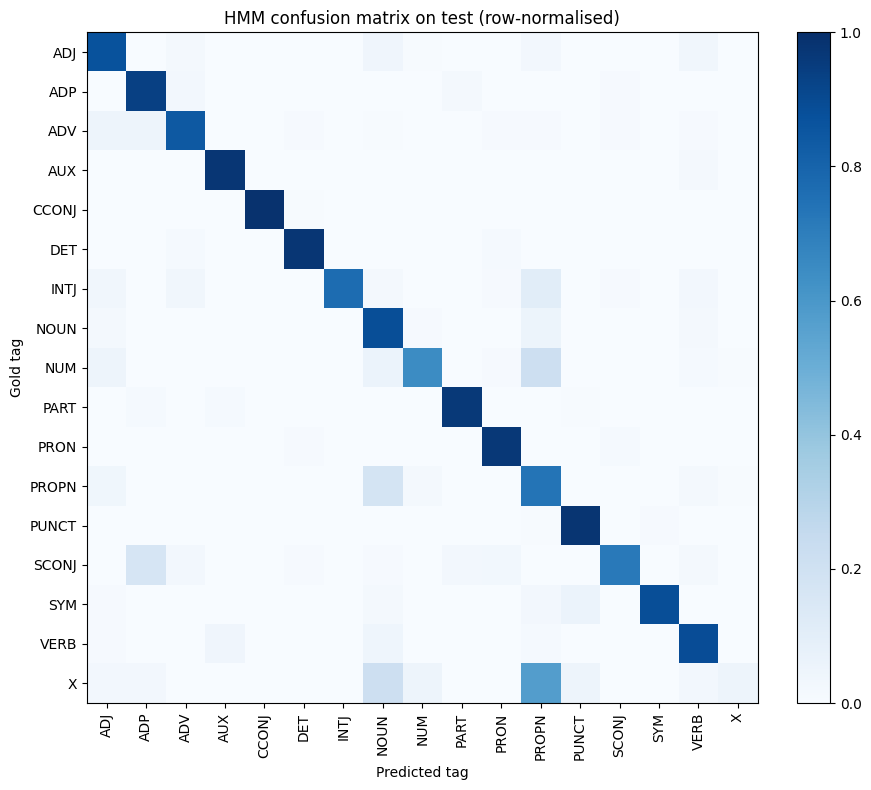

In [16]:
import matplotlib.pyplot as plt

# rows = gold tag, columns = predicted tag; each row is scaled to sum to 1
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(n_tags))
ax.set_xticklabels(tags, rotation=90)
ax.set_yticks(range(n_tags))
ax.set_yticklabels(tags)
ax.set_xlabel("Predicted tag")
ax.set_ylabel("Gold tag")
ax.set_title("HMM confusion matrix on test (row-normalised)")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

## 13. Decoded Sentence Examples

The project asks for decoded sentence examples, so here are 2 sentences the model tagged perfectly and 3 where it made mistakes (gold tag vs predicted tag, with wrong ones marked). The sentences are picked randomly with a fixed seed, so the same ones show up every run.

In [17]:
import random


def show_sentence(i):
    words = [w for w, _ in test[i]]
    gold = [tags[g] for g in test_gold[i]]
    pred = [tags[p] for p in test_preds[i]]
    n_wrong = sum(g != p for g, p in zip(gold, pred))
    print(f"Sentence {i}  ({n_wrong} wrong out of {len(words)})")
    print(f"  {'word':<16}{'gold':<8}{'pred':<8}")
    for w, g, p in zip(words, gold, pred):
        print(f"  {w:<16}{g:<8}{p:<8}{'' if g == p else ' <-- wrong'}")
    print()


random.seed(42)
short = [i for i, s in enumerate(test) if 8 <= len(s) <= 14]
perfect = [i for i in short if test_preds[i] == test_gold[i]]
flawed = [i for i in short if test_preds[i] != test_gold[i]]

print("=== Fully correct examples ===\n")
for i in random.sample(perfect, 2):
    show_sentence(i)

print("=== Examples with mistakes ===\n")
for i in random.sample(flawed, 3):
    show_sentence(i)

=== Fully correct examples ===

Sentence 1433  (0 wrong out of 12)
  word            gold    pred    
  you             PRON    PRON    
  live            VERB    VERB    
  in              ADP     ADP     
  nz              PROPN   PROPN   
  and             CCONJ   CCONJ   
  you             PRON    PRON    
  eat             VERB    VERB    
  mcdonald        PROPN   PROPN   
  s               PART    PART    
  ice             NOUN    NOUN    
  cream           NOUN    NOUN    
  ?               PUNCT   PUNCT   

Sentence 146  (0 wrong out of 8)
  word            gold    pred    
  amin            PROPN   PROPN   
  mohamed         PROPN   PROPN   
  durrani         PROPN   PROPN   
  ,               PUNCT   PUNCT   
  19              NUM     NUM     
  ,               PUNCT   PUNCT   
  toronto         PROPN   PROPN   
  ;               PUNCT   PUNCT   

=== Examples with mistakes ===

Sentence 99  (1 wrong out of 13)
  word            gold    pred    
  it              PRON    PR

## 14. Improving Unknown-Word Handling (HMM v2)

The error analysis showed two weak spots: unknown words (54% accuracy) and PROPN/NOUN/NUM confusions. Right now every unseen word gets the same `<UNK>` emission row, so the model cannot tell "2005" from "Zorbify".

The fix: split `<UNK>` into **buckets based on word shape**, such as digits, capitalised, ALLCAPS, URL-like, hyphenated, and endings like `-ing`, `-ed`, `-ly`, `-s`. Each bucket learns its own emission probabilities from the rare training words that fall into it. Shapes are read from the **original casing**, so capital-letter information is kept even when known words are lowercased.

This box also reloads the data with original casing and wraps vocab + counts into one function, `build_model`, so we can compare settings fairly.

**Expected output:** a list of example words with the bucket each one falls into (e.g. `2005 -> <UNK-NUM>`).

In [18]:
import re

# Words that look like web addresses or e-mails (EWT has plenty of these, usually tagged X)
URL_RE = re.compile(r"(https?://|www\.|@|\.com\b|\.org\b|\.net\b)", re.I)

UNK_CLASSES = ["<UNK>", "<UNK-SYM>", "<UNK-URL>", "<UNK-NUM>", "<UNK-ALLCAP>", "<UNK-CAP>",
               "<UNK-HYPHEN>", "<UNK-ING>", "<UNK-ED>", "<UNK-LY>", "<UNK-S>"]


def unk_class(raw_word):
    """Put an unseen word into a bucket based on its shape, looking at its original casing."""
    w = raw_word
    if not any(ch.isalnum() for ch in w):
        return "<UNK-SYM>"
    if URL_RE.search(w):
        return "<UNK-URL>"
    if any(ch.isdigit() for ch in w):
        return "<UNK-NUM>"
    if len(w) > 1 and w.isupper():
        return "<UNK-ALLCAP>"
    if w[0].isupper():
        return "<UNK-CAP>"
    if "-" in w:
        return "<UNK-HYPHEN>"
    lw = w.lower()
    if lw.endswith("ing") and len(lw) > 4:
        return "<UNK-ING>"
    if lw.endswith("ed") and len(lw) > 3:
        return "<UNK-ED>"
    if lw.endswith("ly") and len(lw) > 3:
        return "<UNK-LY>"
    if lw.endswith("s") and len(lw) > 3:
        return "<UNK-S>"
    return "<UNK>"


# reload the data with original casing, so we can choose later whether to lowercase
raw_train = load_conllu(os.path.join(DATA_DIR, FILES["train"]), lowercase=False)
raw_dev = load_conllu(os.path.join(DATA_DIR, FILES["dev"]), lowercase=False)
raw_test = load_conllu(os.path.join(DATA_DIR, FILES["test"]), lowercase=False)


def build_model(lowercase=True, min_freq=2, shape_unk=False):
    """Rebuild vocab and counts for one setting. Returns an encoder plus the two count tables."""
    norm = (lambda w: w.lower()) if lowercase else (lambda w: w)
    counts = Counter(norm(w) for s in raw_train for w, _ in s)
    unk_tokens = UNK_CLASSES if shape_unk else ["<UNK>"]
    vocab_m = unk_tokens + sorted(w for w, c in counts.items() if c >= min_freq)
    w2i = {w: i for i, w in enumerate(vocab_m)}
    unk_of = unk_class if shape_unk else (lambda w: "<UNK>")

    def encode(raw_word):
        w = norm(raw_word)
        return w2i[w] if w in w2i else w2i[unk_of(raw_word)]

    T = np.zeros((n_tags + 2, n_tags + 2))
    E = np.zeros((n_tags, len(vocab_m)))
    for s in raw_train:
        prev = START
        for word, tag in s:
            t = tag2id[tag]
            T[prev, t] += 1
            E[t, encode(word)] += 1      # rare training words land in the UNK buckets here
            prev = t
        T[prev, END] += 1
    return encode, T, E


# a quick look at which bucket some unseen-looking words fall into
for w in ["Zorbify", "2005", "NASA", "http://abc.com", "state-of-the-art", "running", "quickly", "walked", ":-)", "cats"]:
    print(f"{w:<20}{unk_class(w)}")

Zorbify             <UNK-CAP>
2005                <UNK-NUM>
NASA                <UNK-ALLCAP>
http://abc.com      <UNK-URL>
state-of-the-art    <UNK-HYPHEN>
running             <UNK-ING>
quickly             <UNK-LY>
walked              <UNK-ED>
:-)                 <UNK-SYM>
cats                <UNK-S>


## 15. Comparing Settings on Dev

We compare every combination of:
- **lowercase**: True / False
- **shape-based UNK buckets**: off / on
- **min_freq** (words rarer than this become unknown): 1, 2, 3, 5
- **k_emit**: 0.001, 0.01, 0.1 (the best one is kept for each row)

Everything is scored on the **dev** set only. The unseen-word mask is the same for every row, so the unknown-word column is comparable. This takes about 20-60 seconds.

**Expected output:** a table sorted by dev accuracy, with the best row at about `0.9155` dev accuracy.

In [19]:
# flat gold labels and the unseen-word mask for dev (same for every setting, so results are comparable)
dev_gold_flat = np.array([g for gs in dev_gold for g in gs])
dev_unseen_flat = np.array([u for us in dev_unseen for u in us])

rows = []
for lc in (True, False):
    for shape in (False, True):
        for mf in (1, 2, 3, 5):
            encode, T, E = build_model(lc, mf, shape)
            ids = [[encode(w) for w, _ in s] for s in raw_dev]
            best = None
            for ke in (0.001, 0.01, 0.1):
                lA, lB = smooth(T, E, 1.0, ke)
                pred = np.array([p for ps in predict_all(ids, lA, lB) for p in ps])
                a = (pred == dev_gold_flat).mean()
                if best is None or a > best[0]:
                    best = (a, (pred == dev_gold_flat)[dev_unseen_flat].mean(), ke)
            rows.append((best[0], best[1], lc, shape, mf, best[2]))

rows.sort(reverse=True)
print(f"{'dev acc':>8} {'unseen acc':>11}  {'lowercase':<10}{'shape UNK':<11}{'min_freq':<9}{'k_emit'}")
for a, u, lc, shape, mf, ke in rows:
    print(f"{a:>8.4f} {u:>11.4f}  {str(lc):<10}{str(shape):<11}{mf:<9}{ke}")

best_acc, _, best_lc, best_shape, best_mf, best_ke2 = rows[0]
print(f"\nChosen on dev: lowercase={best_lc}, shape_unk={best_shape}, min_freq={best_mf}, k_emit={best_ke2}  ({best_acc:.4f})")

 dev acc  unseen acc  lowercase shape UNK  min_freq k_emit
  0.9155      0.7523  True      True       2        0.001
  0.9130      0.7430  True      True       3        0.001
  0.9097      0.7254  False     True       2        0.001
  0.9073      0.7371  True      True       5        0.01
  0.9055      0.7254  False     True       3        0.001
  0.8969      0.7272  False     True       5        0.001
  0.8949      0.5427  True      False      2        0.001
  0.8928      0.5504  False     False      2        0.001
  0.8885      0.5398  True      False      3        0.001
  0.8853      0.5509  False     False      3        0.001
  0.8812      0.3144  True      True       1        0.1
  0.8811      0.3144  True      False      1        0.1
  0.8778      0.5422  True      False      5        0.01
  0.8749      0.2670  False     True       1        0.001
  0.8749      0.2670  False     False      1        0.001
  0.8700      0.5445  False     False      5        0.001

Chosen on dev: low

## 16. Final Test Result: HMM v1 vs HMM v2

HMM v2 uses the setting chosen on dev. It is evaluated on the test set once, and compared with the v1 baseline from section 10 on the same three metrics. We also show how the F1 of each tag changed, and how the biggest PROPN/NOUN confusion shrank.

**Expected output:** v2 accuracy about `0.9224`, macro F1 about `0.8553`, unknown-word accuracy about `0.7572`.

In [20]:
# HMM v2 on the test set, using the setting picked on dev
encode2, T2, E2 = build_model(best_lc, best_mf, best_shape)
log_A2, log_B2 = smooth(T2, E2, 1.0, best_ke2)
test_ids2 = [[encode2(w) for w, _ in s] for s in raw_test]
test_preds2 = predict_all(test_ids2, log_A2, log_B2)
y_pred2 = np.array([p for ps in test_preds2 for p in ps])

acc2 = (y_true == y_pred2).mean()
f1_2 = f1_score(y_true, y_pred2, average="macro", labels=range(n_tags), zero_division=0)
unk2 = (y_true == y_pred2)[unseen].mean()
unk1 = (y_true == y_pred)[unseen].mean()

print(f"{'Test metric':<22}{'HMM v1':>10}{'HMM v2':>10}")
print(f"{'Token accuracy':<22}{acc:>10.4f}{acc2:>10.4f}")
print(f"{'Macro F1':<22}{macro_f1:>10.4f}{f1_2:>10.4f}")
print(f"{'Unknown-word accuracy':<22}{unk1:>10.4f}{unk2:>10.4f}")

# per-tag F1 before and after, biggest improvements first
f1_v1 = f1_score(y_true, y_pred, average=None, labels=range(n_tags), zero_division=0)
f1_v2 = f1_score(y_true, y_pred2, average=None, labels=range(n_tags), zero_division=0)
print(f"\n{'tag':<8}{'F1 v1':>8}{'F1 v2':>8}{'change':>9}")
for i in np.argsort(-(f1_v2 - f1_v1)):
    print(f"{tags[i]:<8}{f1_v1[i]:>8.3f}{f1_v2[i]:>8.3f}{f1_v2[i] - f1_v1[i]:>+9.3f}")

# the biggest confusion from before, and how it changed
cm2 = confusion_matrix(y_true, y_pred2, labels=range(n_tags))
pn, nn = tag2id["PROPN"], tag2id["NOUN"]
print(f"\nPROPN -> NOUN mistakes: {cm[pn, nn]} -> {cm2[pn, nn]}")
print(f"NOUN -> PROPN mistakes: {cm[nn, pn]} -> {cm2[nn, pn]}")

Test metric               HMM v1    HMM v2
Token accuracy            0.9003    0.9224
Macro F1                  0.8304    0.8553
Unknown-word accuracy     0.5351    0.7572

tag        F1 v1   F1 v2   change
NUM        0.711   0.918   +0.206
PROPN      0.743   0.848   +0.105
NOUN       0.869   0.895   +0.025
VERB       0.893   0.913   +0.020
ADJ        0.858   0.878   +0.020
SCONJ      0.754   0.763   +0.009
ADV        0.857   0.865   +0.008
SYM        0.791   0.798   +0.008
INTJ       0.834   0.839   +0.005
X          0.062   0.067   +0.005
PUNCT      0.987   0.991   +0.004
ADP        0.931   0.936   +0.004
PART       0.939   0.942   +0.003
DET        0.975   0.976   +0.001
PRON       0.971   0.971   +0.000
CCONJ      0.993   0.993   +0.000
AUX        0.949   0.948   -0.002

PROPN -> NOUN mistakes: 368 -> 266
NOUN -> PROPN mistakes: 223 -> 156


## 17. Saving Results for the BiLSTM Comparison

The final comparison with the BiLSTM has to use exactly the same data and metrics. This box saves two files:

- `hmm_results.json`: settings, test metrics (v1 and v2), per-tag F1, and the definition of "unknown word"
- `hmm_test_predictions.json`: for every test sentence, the words, gold tags and HMM v2 predictions, so errors can be compared sentence by sentence

In Colab the files appear in the left **Files** panel. Download them from there and share them with your DL partner.

In [21]:
import json

per_tag = {tags[i]: {"f1_v1": round(float(f1_v1[i]), 4), "f1_v2": round(float(f1_v2[i]), 4)} for i in range(n_tags)}

results = {
    "dataset": "UD English EWT (official train/dev/test split)",
    "tags": tags,
    "sizes": {"train_sentences": len(raw_train), "dev_sentences": len(raw_dev), "test_sentences": len(raw_test)},
    "hmm_v1": {"lowercase": True, "min_freq": 2, "shape_unk": False, "k_trans": best_kt, "k_emit": best_ke,
               "test_accuracy": round(float(acc), 4), "test_macro_f1": round(float(macro_f1), 4),
               "test_unknown_word_accuracy": round(float(unk1), 4)},
    "hmm_v2": {"lowercase": best_lc, "min_freq": best_mf, "shape_unk": best_shape, "k_trans": 1.0, "k_emit": best_ke2,
               "test_accuracy": round(float(acc2), 4), "test_macro_f1": round(float(f1_2), 4),
               "test_unknown_word_accuracy": round(float(unk2), 4)},
    "per_tag_f1": per_tag,
    "unknown_word_definition": "test word (lowercased) that never appears in the train split",
}

with open("hmm_results.json", "w") as f:
    json.dump(results, f, indent=2)

# predicted tags for every test sentence, so the BiLSTM can be compared sentence by sentence
predictions = [{"words": [w for w, _ in s], "gold": [tags[g] for g in gs], "hmm_v2": [tags[p] for p in ps]}
               for s, gs, ps in zip(raw_test, test_gold, test_preds2)]
with open("hmm_test_predictions.json", "w") as f:
    json.dump(predictions, f)

print("Saved hmm_results.json and hmm_test_predictions.json")
print(json.dumps({k: results[k] for k in ("hmm_v1", "hmm_v2")}, indent=2))

Saved hmm_results.json and hmm_test_predictions.json
{
  "hmm_v1": {
    "lowercase": true,
    "min_freq": 2,
    "shape_unk": false,
    "k_trans": 1.0,
    "k_emit": 0.001,
    "test_accuracy": 0.9003,
    "test_macro_f1": 0.8304,
    "test_unknown_word_accuracy": 0.5351
  },
  "hmm_v2": {
    "lowercase": true,
    "min_freq": 2,
    "shape_unk": true,
    "k_trans": 1.0,
    "k_emit": 0.001,
    "test_accuracy": 0.9224,
    "test_macro_f1": 0.8553,
    "test_unknown_word_accuracy": 0.7572
  }
}


## 18. Per-Tag F1 Chart: HMM v1 vs HMM v2

A visual version of the per-tag table from section 16, sorted from the easiest tag to the hardest. The big jumps for NUM and PROPN show where the shape-based `<UNK>` buckets helped. The lone near-zero bar is the rare tag X.

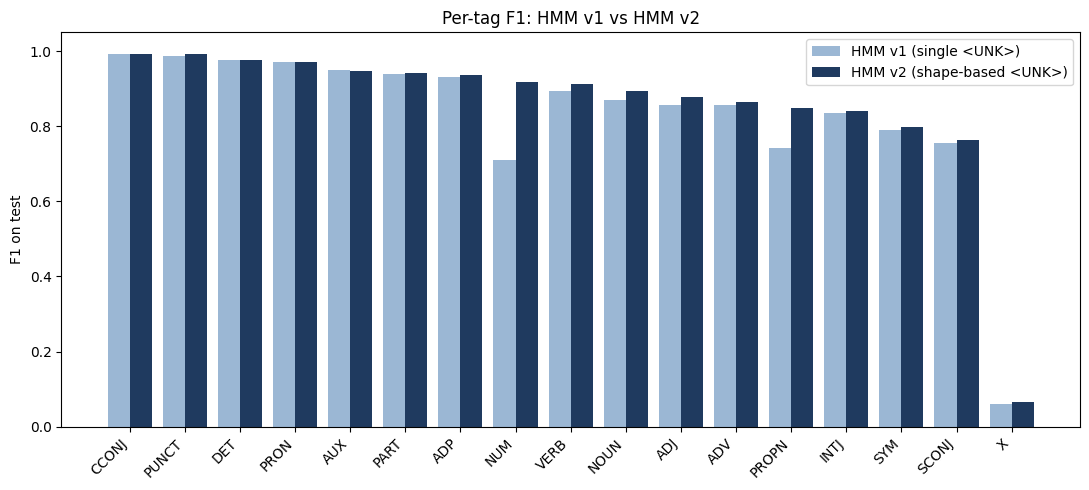

In [22]:
import matplotlib.pyplot as plt

# tags sorted by their v2 F1 so the chart reads from easiest to hardest
order = np.argsort(-f1_v2)
x = np.arange(n_tags)
w = 0.4

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - w / 2, f1_v1[order], w, label="HMM v1 (single <UNK>)", color="#9bb7d4")
ax.bar(x + w / 2, f1_v2[order], w, label="HMM v2 (shape-based <UNK>)", color="#1f3a5f")
ax.set_xticks(x)
ax.set_xticklabels([tags[i] for i in order], rotation=45, ha="right")
ax.set_ylabel("F1 on test")
ax.set_ylim(0, 1.05)
ax.set_title("Per-tag F1: HMM v1 vs HMM v2")
ax.legend()
plt.tight_layout()
plt.show()

## 19. Decoded Examples: HMM v1 vs HMM v2

Three test sentences where v2 fixed the mistakes made by v1, and one where v2 is still wrong. The last one is worth reading: "do" is a **known** word, yet it gets tagged VERB instead of AUX. Smoothing and `<UNK>` buckets can't fix that kind of error, because the HMM only looks at the previous tag.

In [23]:
import random


def show_both(i):
    words = [w for w, _ in raw_test[i]]
    gold = [tags[g] for g in test_gold[i]]
    p1 = [tags[p] for p in test_preds[i]]
    p2 = [tags[p] for p in test_preds2[i]]
    print(f"Sentence {i}  (v1 wrong: {sum(g != p for g, p in zip(gold, p1))}, v2 wrong: {sum(g != p for g, p in zip(gold, p2))})")
    print(f"  {'word':<16}{'gold':<8}{'v1':<8}{'v2':<8}")
    for w, g, a, b in zip(words, gold, p1, p2):
        note = "  <-- v2 fixed it" if a != g and b == g else "  <-- v2 wrong" if b != g else ""
        print(f"  {w:<16}{g:<8}{a:<8}{b:<8}{note}")
    print()


random.seed(7)
short = [i for i, s in enumerate(raw_test) if 8 <= len(s) <= 14]
wrong1 = lambda i: sum(g != p for g, p in zip(test_gold[i], test_preds[i]))
wrong2 = lambda i: sum(g != p for g, p in zip(test_gold[i], test_preds2[i]))

fixed = [i for i in short if wrong1(i) > 0 and wrong2(i) == 0]
still_wrong = [i for i in short if wrong2(i) > 0]

print("=== Sentences where v2 fixed the mistakes of v1 ===\n")
for i in random.sample(fixed, 3):
    show_both(i)

print("=== A sentence v2 still gets wrong ===\n")
for i in random.sample(still_wrong, 1):
    show_both(i)

=== Sentences where v2 fixed the mistakes of v1 ===

Sentence 650  (v1 wrong: 1, v2 wrong: 0)
  word            gold    v1      v2      
  Here            ADV     ADV     ADV     
  is              AUX     AUX     AUX     
  a               DET     DET     DET     
  revised         VERB    VERB    VERB    
  draft           NOUN    NOUN    NOUN    
  of              ADP     ADP     ADP     
  the             DET     DET     DET     
  CDWR            NOUN    ADJ     NOUN      <-- v2 fixed it
  risk            NOUN    NOUN    NOUN    
  memo            NOUN    NOUN    NOUN    
  .               PUNCT   PUNCT   PUNCT   

Sentence 484  (v1 wrong: 1, v2 wrong: 0)
  word            gold    v1      v2      
  I               PRON    PRON    PRON    
  am              AUX     AUX     AUX     
  bringing        VERB    VERB    VERB    
  two             NUM     NUM     NUM     
  of              ADP     ADP     ADP     
  my              PRON    PRON    PRON    
  girlfriends     NOUN    VERB